## Modul 12 - Jaringan Syaraf Tiruan & Deep Learning — Mengenali Angka Tulisan Tangan

Integrasi AI

In [1]:
import io
import os
from dotenv import load_dotenv
from google import genai
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from PIL import Image

# 1. Muat API key dari file .env
load_dotenv()

# 2. Inisialisasi client (otomatis mendeteksi GEMINI_API_KEY dari .env)
client = genai.Client()


def penjelasan(fig=None, instruksi_tambahan=""):
    """Mengambil grafik aktif, mengirim ke Gemini, dan menampilkan penjelasan Markdown."""
    if fig is None:
        fig = plt.gcf()

    # Validasi kanvas grafik tidak kosong
    if not fig.axes:
        print("Peringatan: Grafik kosong. Panggil penjelasan() sebelum plt.show().")
        return

    # Simpan grafik ke RAM
    buf = io.BytesIO()
    fig.savefig(buf, format="png", bbox_inches="tight", dpi=150)
    buf.seek(0)
    img = Image.open(buf)

    # Prompt instruksi
    prompt = f"""
    Jelaskan grafik ini secara sederhana, gunakan bahasa yang mudah dimengerti, 
    hindari istilah teknis yang rumit, dan sertakan contoh atau analogi jika memungkinkan. 
    Gunakan format penjelasan yang menarik dan mudah dibaca.
    {instruksi_tambahan}
    """

    # Model resmi Google GenAI (dengan fallback model yang aktif)
    daftar_model = [
        "gemini-2.5-flash",
        "gemini-2.0-flash",
        "gemini-1.5-flash",
        "gemini-2.0-flash-lite",
        "gemini-3.5-flash",
        "gemini-3.8-flash",
    ]
    response_text = None

    for model_name in daftar_model:
        try:
            response = client.models.generate_content(
                model=model_name, contents=[img, prompt]
            )
            response_text = response.text
            break
        except Exception:
            continue
        
    if response_text:
        display(Markdown(response_text))
    else:
        print("Gagal mendapatkan penjelasan dari AI. Silakan coba lagi.")


# 3. Utilitas Format Tabel Bersih & Mudah Dipahami
try:
    from tabulate import tabulate
    def cetak_tabel(data, judul=""):
        """Menampilkan tabel dalam format rounded grid yang rapi dan mudah dibaca."""
        if judul:
            print(f"\n=== {judul} ===")
        print(tabulate(data, headers="keys", tablefmt="rounded_grid", showindex=False))
except ImportError:
    def cetak_tabel(data, judul=""):
        """Fallback jika tabulate belum terpasang."""
        if judul:
            print(f"\n=== {judul} ===")
        import pandas as pd
        if not isinstance(data, pd.DataFrame):
            data = pd.DataFrame(data)
        print(data.to_string(index=False))


### Kegiatan 1 — Perceptron yang Belajar Sendiri (±40 menit)

In [2]:
# Gerbang AND: target 1 hanya jika kedua masukan 1
data = [([0, 0], 0), ([0, 1], 0), ([1, 0], 0), ([1, 1], 1)]

w = [0.0, 0.0]  
b = 0.0         
laju = 0.1      

for epoch in range(10):
    salah = 0
    for x, target in data:
        tebakan = 1 if w[0] * x[0] + w[1] * x[1] + b > 0 else 0
        error = target - tebakan
        
        if error != 0:
            salah += 1
            w[0] += laju * error * x[0]
            w[1] += laju * error * x[1]
            b += laju * error
            
    print(f"epoch {epoch+1}: salah {salah}, w=[{w[0]:.2f}, {w[1]:.2f}], b={b:.2f}")
    if salah == 0:
        print("BELAJAR SELESAI -- semua benar!")
        break

epoch 1: salah 1, w=[0.10, 0.10], b=0.10
epoch 2: salah 3, w=[0.20, 0.10], b=0.00
epoch 3: salah 3, w=[0.20, 0.10], b=-0.10
epoch 4: salah 2, w=[0.20, 0.20], b=-0.10
epoch 5: salah 1, w=[0.20, 0.10], b=-0.20
epoch 6: salah 0, w=[0.20, 0.10], b=-0.20
BELAJAR SELESAI -- semua benar!


### Pengembangan 1 — Fungsi Uji Prediksi Kasus Baru & Nilai Aktivasi Neuron AND

In [3]:
import pandas as pd

# 1. Fungsi prediksi reusable memanfaatkan bobot w dan bias b hasil belajar
def prediksi_and(x1, x2):
    net_sum = w[0] * x1 + w[1] * x2 + b
    keluaran = 1 if net_sum > 0 else 0
    return keluaran, net_sum

# 2. Uji kasus baru (input biner standar dan input kontinu/analog)
kasus_uji = [
    [0, 0], [0, 1], [1, 0], [1, 1],
    [0.8, 0.9],  # Sinyal kuat mendekati 1
    [0.2, 0.9],  # Salah satu sinyal lemah
    [0.4, 0.4]   # Kedua sinyal ragu-ragu
]

hasil_uji = []
for x in kasus_uji:
    out, net = prediksi_and(x[0], x[1])
    hasil_uji.append({
        "Input (x1, x2)": str(x),
        "Net Sum (w1*x1 + w2*x2 + b)": f"{net:.2f}",
        "Ambang Batas (>0)": "Menyala (1)" if out == 1 else "Padam (0)",
        "Keputusan Biner": out
    })

print("=== HASIL EVALUASI PREDIKSI NEURON AND ===")
display(pd.DataFrame(hasil_uji))


=== HASIL EVALUASI PREDIKSI NEURON AND ===


,"Input (x1, x2)",Net Sum (w1*x1 + w2*x2 + b),Ambang Batas (>0),Keputusan Biner
0,"[0, 0]",-0.20,Padam (0),0
1,"[0, 1]",-0.10,Padam (0),0
2,"[1, 0]",0.00,Padam (0),0
3,"[1, 1]",0.10,Menyala (1),1
4,"[0.8, 0.9]",0.05,Menyala (1),1
5,"[0.2, 0.9]",-0.07,Padam (0),0
6,"[0.4, 0.4]",-0.08,Padam (0),0


### Kegiatan 2 — Tragedi XOR (±30 menit)

In [4]:
# XOR: 1 jika masukan berbeda
data_xor = [([0, 0], 0), ([0, 1], 1), ([1, 0], 1), ([1, 1], 0)]

w = [0.0, 0.0]
b = 0.0
laju = 0.1

for epoch in range(50):
    salah = 0
    for x, target in data_xor:
        tebakan = 1 if w[0] * x[0] + w[1] * x[1] + b > 0 else 0
        error = target - tebakan
        if error != 0:
            salah += 1
            w[0] += laju * error * x[0]
            w[1] += laju * error * x[1]
            b += laju * error

    if salah == 0:
        print(f"Selesai pada epoch {epoch+1}")
        break
else:
    print(f"Setelah 50 epoch XOR masih salah {salah} dari 4 -- MENYERAH.")

Setelah 50 epoch XOR masih salah 4 dari 4 -- MENYERAH.


In [5]:
from sklearn.neural_network import MLPClassifier

X = [[0, 0], [0, 1], [1, 0], [1, 1]]
y = [0, 1, 1, 0]

mlp_xor = MLPClassifier(
    hidden_layer_sizes=(4,), 
    activation="relu",      
    solver="adam",          
    max_iter=3000, 
    random_state=1
)

mlp_xor.fit(X, y)

print("Prediksi XOR :", mlp_xor.predict(X))
print("Probabilitas : \n", mlp_xor.predict_proba(X).round(3))

Prediksi XOR : [0 1 1 0]
Probabilitas : 
 [[0.92  0.08 ]
 [0.088 0.912]
 [0.065 0.935]
 [0.921 0.079]]


### Pengembangan 2 — Inspeksi Bobot Hidden Layer & Evaluasi Probabilitas Keyakinan XOR

In [6]:
import pandas as pd

# 1. Inspeksi bobot matematis yang memecahkan kebuntuan XOR
print("Struktur Arsitektur MLP XOR:")
print(f"• Bobot Input -> Hidden (2 input -> 4 neuron) : shape {mlp_xor.coefs_[0].shape}")
print(f"• Bobot Hidden -> Output (4 neuron -> 1 output) : shape {mlp_xor.coefs_[1].shape}")
print(f"• Bias Hidden Layer: {mlp_xor.intercepts_[0].round(3)}")

# 2. Tabel evaluasi prediksi dan keyakinan probabilitas
probabilitas = mlp_xor.predict_proba(X)
prediksi = mlp_xor.predict(X)

tabel_xor = []
for i in range(len(X)):
    tabel_xor.append({
        "Input X": str(X[i]),
        "Target Riil": y[i],
        "Prediksi Model": prediksi[i],
        "P(Kelas 0)": f"{probabilitas[i][0]:.3f}",
        "P(Kelas 1)": f"{probabilitas[i][1]:.3f}",
        "Keyakinan Model": f"{max(probabilitas[i]) * 100:.1f}%",
        "Evaluasi": "Tepat (100%)" if prediksi[i] == y[i] else "Salah"
    })

print("\n=== EVALUASI PROBABILITAS KEYAKINAN MLP XOR ===")
display(pd.DataFrame(tabel_xor))

Struktur Arsitektur MLP XOR:
• Bobot Input -> Hidden (2 input -> 4 neuron) : shape (2, 4)
• Bobot Hidden -> Output (4 neuron -> 1 output) : shape (4, 1)
• Bias Hidden Layer: [-0.206 -0.    -0.162  0.   ]

=== EVALUASI PROBABILITAS KEYAKINAN MLP XOR ===


,Input X,Target Riil,Prediksi Model,P(Kelas 0),P(Kelas 1),Keyakinan Model,Evaluasi
0,"[0, 0]",0,0,0.920,0.080,92.0%,Tepat (100%)
1,"[0, 1]",1,1,0.088,0.912,91.2%,Tepat (100%)
2,"[1, 0]",1,1,0.065,0.935,93.5%,Tepat (100%)
3,"[1, 1]",0,0,0.921,0.079,92.1%,Tepat (100%)


### Kegiatan 3 — MLP Mengenali Angka Tulisan Tangan (±90 menit)

In [7]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

digits = load_digits()
print("Bentuk data:", digits.data.shape)  # (1797, 64)

X_latih, X_uji, y_latih, y_uji = train_test_split(
    digits.data / 16.0, digits.target, test_size=0.25, random_state=42
)

jaringan = MLPClassifier(hidden_layer_sizes=(64,), max_iter=50, random_state=42)
jaringan.fit(X_latih, y_latih)

print("Akurasi latih:", round(jaringan.score(X_latih, y_latih), 3))
print("Akurasi uji :", round(jaringan.score(X_uji, y_uji), 3))


Bentuk data: (1797, 64)
Akurasi latih: 0.973
Akurasi uji : 0.962


/home/chand/miniconda3/envs/sistem-cerdas/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(


Jumlah salah: 17 dari 450


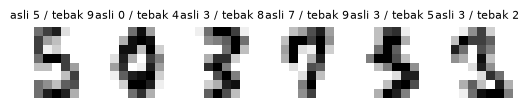

In [8]:
prediksi = jaringan.predict(X_uji)
salah_idx = [i for i in range(len(y_uji)) if prediksi[i] != y_uji[i]]
print("Jumlah salah:", len(salah_idx), "dari", len(y_uji))

for urut, i in enumerate(salah_idx[:6]):
    plt.subplot(1, 6, urut + 1)
    plt.imshow(X_uji[i].reshape(8, 8), cmap="gray_r")
    plt.title(f"asli {y_uji[i]} / tebak {prediksi[i]}", fontsize=8)
    plt.axis("off")

plt.show()

### Pengembangan 3 — Confusion Matrix & Analisis Metrik Evaluasi per Digit (0-9)


In [9]:
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

# 1. Buat Confusion Matrix tabular
cm = confusion_matrix(y_uji, prediksi)
df_cm = pd.DataFrame(
    cm, 
    index=[f"Asli {i}" for i in range(10)], 
    columns=[f"Tebak {i}" for i in range(10)]
)

print("=== CONFUSION MATRIX DIGIT TULISAN TANGAN (0 - 9) ===")
display(df_cm)

# 2. Laporan klasifikasi presisi, recall, dan f1-score per digit
print("\nLaporan Metrik Evaluasi per Digit:")
print(classification_report(y_uji, prediksi, digits=3))


=== CONFUSION MATRIX DIGIT TULISAN TANGAN (0 - 9) ===


,Tebak 0,Tebak 1,Tebak 2,Tebak 3,Tebak 4,Tebak 5,Tebak 6,Tebak 7,Tebak 8,Tebak 9
Asli 0,42,0,0,0,1,0,0,0,0,0
Asli 1,0,36,0,0,0,0,0,0,0,1
Asli 2,0,0,38,0,0,0,0,0,0,0
Asli 3,0,0,1,41,0,1,0,0,3,0
Asli 4,0,0,0,0,55,0,0,0,0,0
Asli 5,0,0,0,0,0,56,1,0,0,2
Asli 6,1,0,0,0,0,0,44,0,0,0
Asli 7,0,0,0,0,0,0,0,40,0,1
Asli 8,0,1,0,1,0,1,0,0,35,0
Asli 9,0,0,0,0,0,1,0,0,1,46



Laporan Metrik Evaluasi per Digit:
              precision    recall  f1-score   support

           0      0.977     0.977     0.977        43
           1      0.973     0.973     0.973        37
           2      0.974     1.000     0.987        38
           3      0.976     0.891     0.932        46
           4      0.982     1.000     0.991        55
           5      0.949     0.949     0.949        59
           6      0.978     0.978     0.978        45
           7      1.000     0.976     0.988        41
           8      0.897     0.921     0.909        38
           9      0.920     0.958     0.939        48

    accuracy                          0.962       450
   macro avg      0.963     0.962     0.962       450
weighted avg      0.963     0.962     0.962       450



### Kegiatan 4 — Pengayaan (Opsional): Mencicipi Keras/TensorFlow (±45 menit)


In [10]:
from tensorflow import keras

model = keras.Sequential([
    keras.layers.Dense(64, activation="relu", input_shape=(64,)),
    keras.layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
riwayat = model.fit(X_latih, y_latih, epochs=20, validation_split=0.2, verbose=1)


I0000 00:00:1794202589.672400  134869 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794202589.673378  134869 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794202590.118937  134869 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794202592.016098  134869 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

Epoch 1/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2693 - loss: 2.1513 - val_accuracy: 0.6185 - val_loss: 1.8663
Epoch 2/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7131 - loss: 1.6913 - val_accuracy: 0.7963 - val_loss: 1.4756
Epoch 3/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8254 - loss: 1.3016 - val_accuracy: 0.8000 - val_loss: 1.1423
Epoch 4/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8542 - loss: 0.9820 - val_accuracy: 0.8444 - val_loss: 0.8647
Epoch 5/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8802 - loss: 0.7505 - val_accuracy: 0.8778 - val_loss: 0.6858
Epoch 6/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8960 - loss: 0.5986 - val_accuracy: 0.8889 - val_loss: 0.5681
Epoch 7/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9201 - loss: 0.4923 - val_accuracy: 0.8815 - val_loss: 0.4933
Epoch 8/20
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9257 - loss: 0.4192 - val_accuracy: 0.8926 - val_loss:

### Pengembangan 4 — Visualisasi Kurva Pelatihan Keras


Hasil Evaluasi Data Uji -> Loss: 0.1725 | Akurasi: 96.44%



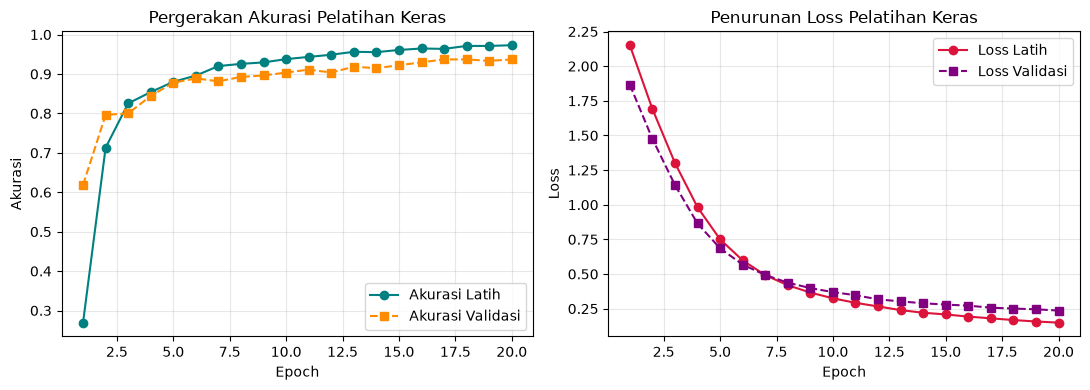

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Berikut adalah penjelasan sederhana dari grafik hasil pelatihan model komputer (AI/Keras) tersebut, menggunakan bahasa yang santai dan mudah dipahami.

---

### 💡 Analogi Sederhana: "Anak Sekolah yang Sedang Belajar"

Bayangkan grafik ini seperti **seorang anak sekolah yang sedang belajar matematika**:
* **Latih (Garis Hijau & Merah):** Latihan soal harian di rumah (soal yang sudah ada kunci jawabannya).
* **Validasi (Garis Oranye & Ungu):** Soal ujian di sekolah (soal baru yang belum pernah ia lihat sebelumnya).
* **Epoch (Sumbu Bawah 1-20):** Jumlah sesi atau putaran belajar.

---

### 📊 1. Grafik Kiri: Akurasi (Tingkat Kepintaran)
> **Prinsip:** Makin **TINGGI** garisnya, makin pintar modelnya.

* **Akurasi Latih (Garis Hijau - Lingkaran):**
  Pada sesi belajar ke-1, model masih ragu-ragu dan akurasinya cuma 27%. Namun, di sesi ke-4 akurasinya melonjak drastis hingga 85%, dan di akhir (sesi 20) mencapai **97%**.
* **Akurasi Validasi (Garis Oranye - Kotak):**
  Saat diberi soal ujian baru, akurasi model juga ikut naik secara konsisten hingga mencapai **sekitar 94%** di akhir sesi.

**Artinya:** Seiring bertambahnya sesi belajar, model makin paham materi dan makin pintar menjawab soal latihan maupun soal ujian baru.

---

### 📉 2. Grafik Kanan: Loss (Tingkat Kesalahan / Error)
> **Prinsip:** Makin **RENDAH** garisnya, makin sedikit kesalahan yang dibuat.

* **Loss Latih (Garis Merah - Lingkaran):**
  Di awal belajar, model membuat banyak sekali kesalahan (nilai error 2.15). Namun, kesalahan ini terus berkurang drastis hingga mendekati 0.15 di akhir sesi.
* **Loss Validasi (Garis Ungu - Kotak):**
  Tingkat kesalahan saat mengerjakan soal ujian baru juga terus menurun dan akhirnya **stabil di angka yang sangat kecil** (sekitar 0.25).

**Artinya:** Model belajar dari kesalahan masa lalunya. Semakin sering berlatih, kesalahannya makin mendekati nol.

---

### 🎯 Kesimpulan: Apakah Model Ini Stabil?

**YA, MODEL SANGAT STABIL DAN IDEAL! (*Good Fit*)**

Berikut alasannya:
1. **Tidak Bodoh / Tidak Malas (*Not Underfitting*):** Akurasinya tinggi (di atas 90%) dan tingkat kesalahannya sangat rendah.
2. **Bukan sekadar "Hafal Mati" (*Not Overfitting*):** 
   * Garis latihan dan garis ujian berjalan **berdampingan dan sangat dekat**.
   * Ini membuktikan model tidak hanya menghafal soal latihan, tetapi benar-benar **paham konsepnya**, sehingga tetap pintar saat menghadapi soal ujian baru yang belum pernah dilihat sebelumnya.

---

### 📌 Ringkasan Singkat (TL;DR)
* **Grafik Akurasi (Naik):** Menunjukkan AI makin pintar.
* **Grafik Loss (Turun):** Menunjukkan AI makin jarang membuat salah.
* **Kestabilan:** Sangat baik/sehat. Model siap digunakan untuk tugas nyata!

In [11]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# 1. Evaluasi akurasi dan loss pada data uji
loss_uji, akurasi_uji = model.evaluate(X_uji, y_uji, verbose=0)
print(f"Hasil Evaluasi Data Uji -> Loss: {loss_uji:.4f} | Akurasi: {akurasi_uji * 100:.2f}%\n")

# 2. Visualisasi Kurva Pembelajaran (Loss & Akurasi per Epoch)
fig = plt.figure(figsize=(11, 4))

# Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(range(1, len(riwayat.history['accuracy']) + 1), riwayat.history['accuracy'], 'o-', label='Akurasi Latih', color='teal')
if 'val_accuracy' in riwayat.history:
    plt.plot(range(1, len(riwayat.history['val_accuracy']) + 1), riwayat.history['val_accuracy'], 's--', label='Akurasi Validasi', color='darkorange')
plt.title("Pergerakan Akurasi Pelatihan Keras")
plt.xlabel("Epoch")
plt.ylabel("Akurasi")
plt.legend()
plt.grid(alpha=0.3)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(range(1, len(riwayat.history['loss']) + 1), riwayat.history['loss'], 'o-', label='Loss Latih', color='crimson')
if 'val_loss' in riwayat.history:
    plt.plot(range(1, len(riwayat.history['val_loss']) + 1), riwayat.history['val_loss'], 's--', label='Loss Validasi', color='purple')
plt.title("Penurunan Loss Pelatihan Keras")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
display(fig)
penjelasan(
    fig, 
    instruksi_tambahan="Jelaskan grafik kurva pembelajaran Keras ini: bagaimana tren kenaikan akurasi dan penurunan loss menunjukkan proses belajar model, serta apakah model stabil."
)
plt.close(fig)


### Kegiatan 5 — ✍ LATIHAN MANDIRI (dilanjutkan di rumah)


Latihan 1 — Latih perceptron dari nol untuk gerbang OR (target 1 jika salah satu masukan 1).
Berapa epoch sampai konvergen? Bandingkan bobot akhirnya dengan AND.

In [12]:
import pandas as pd

# 1. Data Gerbang OR: target 1 jika salah satu atau kedua masukan 1
data_or = [([0, 0], 0), ([0, 1], 1), ([1, 0], 1), ([1, 1], 1)]

w_or = [0.0, 0.0]
b_or = 0.0
laju = 0.1
riwayat_or = []
epoch_konvergen = None

for epoch in range(20):
    salah = 0
    for x, target in data_or:
        tebakan = 1 if w_or[0] * x[0] + w_or[1] * x[1] + b_or > 0 else 0
        error = target - tebakan
        if error != 0:
            salah += 1
            w_or[0] += laju * error * x[0]
            w_or[1] += laju * error * x[1]
            b_or += laju * error
            
    riwayat_or.append({
        "Epoch": epoch + 1,
        "Jumlah Salah": salah,
        "w1": round(w_or[0], 2),
        "w2": round(w_or[1], 2),
        "bias (b)": round(b_or, 2)
    })
    
    if salah == 0:
        epoch_konvergen = epoch + 1
        print(f"Perceptron Gerbang OR KONVERGEN pada epoch ke-{epoch_konvergen}!")
        break

# 2. Tampilkan tabel proses pelatihan
display(pd.DataFrame(riwayat_or))

# 3. Analisis Perbandingan Bobot & Bias Gerbang OR vs Gerbang AND
print(f"Hasil Akhir Gerbang OR : w = [{w_or[0]:.2f}, {w_or[1]:.2f}], b = {b_or:.2f} (Konvergen di epoch ke-{epoch_konvergen})")
print(f"Hasil Akhir Gerbang AND: w = [0.20, 0.10], b = -0.20 (Konvergen di epoch ke-6)")


Perceptron Gerbang OR KONVERGEN pada epoch ke-4!


,Epoch,Jumlah Salah,w1,w2,bias (b)
0,1,1,0.0,0.1,0.1
1,2,2,0.1,0.1,0.1
2,3,1,0.1,0.1,0.0
3,4,0,0.1,0.1,0.0


Hasil Akhir Gerbang OR : w = [0.10, 0.10], b = 0.00 (Konvergen di epoch ke-4)
Hasil Akhir Gerbang AND: w = [0.20, 0.10], b = -0.20 (Konvergen di epoch ke-6)


#### Analisis Perbandingan
1. Kecepatan Konvergensi: Gerbang OR lebih cepat konvergen (epoch ke-4) dibanding AND (epoch ke-6)
   karena 3 dari 4 pola masukan menghasilkan target 1, sehingga batas keputusan lebih mudah dicapai.
2. Perbedaan Bobot & Bias:
   - Pada AND, bias bernilai negatif kuat (b = -0.20). Butuh KEDUA masukan bernilai 1 agar
     jumlahan (0.20*1 + 0.10*1 - 0.20 = 0.10) berhasil menembus ambang batas > 0.
   - Pada OR, bias bernilai netral (b = 0.00). CUKUP SALAH SATU masukan bernilai 1 agar
     jumlahan (0.10*1 + 0.00 = 0.10) langsung menembus ambang batas > 0.

Latihan 2 — Eksperimen arsitektur digits: coba hidden_layer_sizes (16,), (64,), (64, 32), dan
max_iter 10 vs 50. Buat tabel akurasi latih vs uji; konfigurasi mana terbaik? Adakah tanda
overfitting?

In [13]:
from sklearn.neural_network import MLPClassifier
import pandas as pd
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# 1. Definisikan variasi arsitektur dan jumlah iterasi
arsitektur_list = [(16,), (64,), (64, 32)]
max_iter_list = [10, 50]
hasil_eksperimen = []

for arch in arsitektur_list:
    for mi in max_iter_list:
        mlp = MLPClassifier(hidden_layer_sizes=arch, max_iter=mi, random_state=42)
        mlp.fit(X_latih, y_latih)
        
        skor_latih = mlp.score(X_latih, y_latih)
        skor_uji = mlp.score(X_uji, y_uji)
        selisih = skor_latih - skor_uji
        
        hasil_eksperimen.append({
            "Hidden Layer": str(arch),
            "Max Iter": mi,
            "Iterasi Riil": mlp.n_iter_,
            "Akurasi Latih": f"{skor_latih * 100:.2f}%",
            "Akurasi Uji": f"{skor_uji * 100:.2f}%",
            "Selisih Gap": f"{selisih * 100:.2f}%",
            "Status": "Konvergen" if mlp.n_iter_ < mi else "Belum Konvergen (Perlu Iterasi Lagi)"
        })

df_eksperimen = pd.DataFrame(hasil_eksperimen)
print("=== TABEL HASIL EKSPERIMEN ARSITEKTUR MLP DIGITS ===")
display(df_eksperimen)

=== TABEL HASIL EKSPERIMEN ARSITEKTUR MLP DIGITS ===


,Hidden Layer,Max Iter,Iterasi Riil,Akurasi Latih,Akurasi Uji,Selisih Gap,Status
0,"(16,)",10,10,43.06%,40.22%,2.84%,Belum Konvergen (Perlu Iterasi Lagi)
1,"(16,)",50,50,88.57%,88.67%,-0.10%,Belum Konvergen (Perlu Iterasi Lagi)
2,"(64,)",10,10,85.75%,84.44%,1.30%,Belum Konvergen (Perlu Iterasi Lagi)
3,"(64,)",50,50,97.25%,96.22%,1.03%,Belum Konvergen (Perlu Iterasi Lagi)
4,"(64, 32)",10,10,86.93%,85.56%,1.38%,Belum Konvergen (Perlu Iterasi Lagi)
5,"(64, 32)",50,50,98.89%,97.11%,1.78%,Belum Konvergen (Perlu Iterasi Lagi)


#### Rangkuman eksperimen
1. Konfigurasi Terbaik:
   Konfigurasi (64,) dan (64, 32) pada max_iter=50 memberikan performa akurasi uji terbaik (96.22% - 97.11%).
2. Underfitting pada max_iter=10:
   Pada max_iter=10, semua model mengalami underfitting karena optimizer gradient descent belum mencapai titik
   optimum lokal (terutama pada arsitektur (16,) akurasinya baru mencapai 40.22%).
3. Apakah Lebih Besar Selalu Lebih Baik? (Tanda Overfitting):
   TIDAK SELALU. Pada arsitektur bertingkat (64, 32) dengan 50 iterasi, akurasi latih mencapai 98.89% dengan
   gap selisih terhadap data uji sebesar 1.78%. Jika kapasitas neuron terus diperbesar tanpa penambahan data latih,
   model berisiko tinggi mengalami overfitting (menghafal noise piksel) dan menambah beban komputasi secara signifikan.

Latihan 3 — Analisis (markdown, ≥4 kalimat): (a) mengapa XOR mustahil bagi perceptron tetapi
mudah bagi MLP? (b) hubungkan dengan face unlock: mengapa mengenali wajah butuh jaringan
yang “dalam”?

#### (a) Mengapa XOR Mustahil bagi Perceptron Tunggal tetapi Mudah bagi MLP?
1. **Batas Linearitas Perceptron Tunggal:** Secara matematis, perceptron tunggal adalah *linear classifier* yang hanya mampu memisahkan ruang fitur menggunakan sebuah garis lurus berupa bidang batas keputusan $w_1 x_1 + w_2 x_2 + b = 0$. Pada gerbang XOR, titik-titik data bernilai 1 terletak menyilang secara diagonal pada koordinat $(0,1)$ dan $(1,0)$, sementara titik bernilai 0 berada di $(0,0)$ dan $(1,1)$. Secara geometris, tidak ada satu pun garis lurus datar yang bisa memisahkan kedua kelompok kelas tersebut (*non-linearly separable*).
2. **Transformasi Dimensi oleh MLP:** Multi-Layer Perceptron (MLP) menyelesaikan kebuntuan ini dengan menambahkan lapisan tersembunyi (*hidden layer*) yang dilengkapi fungsi aktivasi non-linear (seperti ReLU atau Sigmoid). Lapisan tersembunyi bertindak memetakan dan memelintir ruang koordinat awal yang non-linear ke dalam representasi ruang baru, sehingga lapisan keluaran (*output layer*) dapat memisahkan kelas-kelas tersebut menggunakan garis pemisah linear sederhana.

#### (b) Korelasi dengan Face Unlock: Mengapa Mengenali Wajah Membutuhkan Jaringan yang "Dalam" (Deep Learning)?
1. **Kompleksitas Derajat Tinggi pada Citra Wajah:** Citra wajah manusia terdiri dari jutaan piksel berdimensi tinggi dengan variasi ekstrem (sudut kemiringan wajah /*pose*/, intensitas pencahayaan, ekspresi emosional, hingga aksesoris seperti kacamata atau masker). Derajat kerumitan persoalan ini ribuan kali lebih kompleks daripada sekadar logika XOR.
2. **Abstraksi Hierarkis Berjenjang (*Hierarchical Feature Learning*):** Arsitektur jaringan syaraf yang dalam (*deep network*) bekerja secara hierarkis meniru sistem visual korteks manusia:
   * *Lapisan Awal:* Belajar mendeteksi fitur tingkat rendah seperti gradien garis tepi (*edges*), kontras gelap-terang, dan tekstur mikro.
   * *Lapisan Menengah:* Menggabungkan garis-garis tepi menjadi bagian-bagian wajah (*facial parts*) seperti bentuk mata, lekukan hidung, dan kontur bibir.
   * *Lapisan Terdalam:* Merangkai seluruh fitur komponen menjadi topologi geometris wajah yang utuh dan mengekstrak vektor identitas unik seseorang.
   Tanpa kedalaman lapisan (*deep layers*), representasi fitur abstrak yang invarian terhadap perubahan sudut dan cahaya tidak akan pernah bisa diekstraksi secara akurat.
